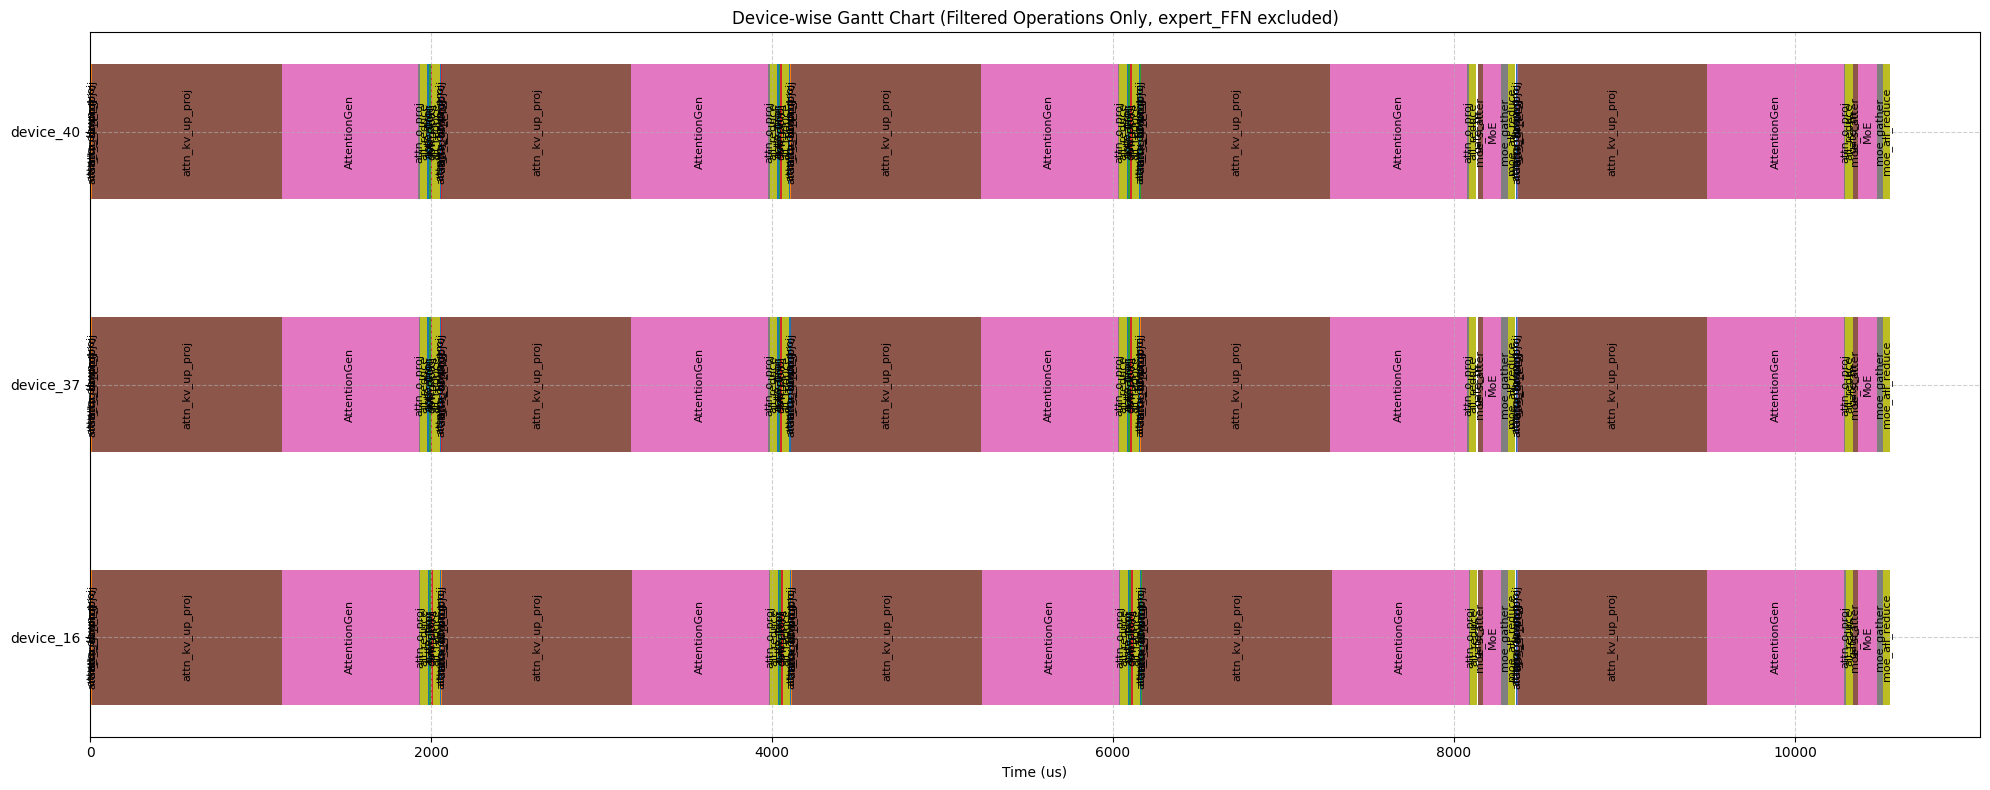

In [1]:
import matplotlib.pyplot as plt
import re
import os
from collections import defaultdict


# Define input log files for each device

gantt_directory = "../build/gantt"

# Define allowed operations (including wildcard match for expert_FFN)
allowed_operations = {
    "attn_q_down_proj",
    "attn_kv_down_proj",
    "attn_kr_proj",
    "attn_q_up_proj",
    "attn_qr_proj",
    "attn_kv_up_proj",
    "attn_qkv_proj",
    "AttentionSum",
    "AttentionGen",
    "gate_fn",
    "moe_scatter",
    "attn_o_proj",
    "all_reduce",
    "gate_proj",
    "activation",
    "up_proj",
    "down_proj",
    "moe_gather",
    "moe_all_reduce"
}

# Store parsed tasks per device
device_data = defaultdict(list)

def parse_log_file(file_path, device_name):
    with open(file_path, 'r') as f:
        lines = f.readlines()

    parsed_tasks = []
    base_indent = None
    skip_indent = None

    for i, line in enumerate(lines):
        line = line.replace('\t', '    ')  # Convert tabs to spaces
        indent_level = len(line) - len(line.lstrip(' '))

        if base_indent is None:
            base_indent = indent_level

        relative_indent = indent_level - base_indent
        stripped_line = line.strip()

        match = re.match(r'^(.*?)\|\s*([\d.]+)us\s*\|\s*([\d.]+)\s*-\s*([\d.]+)', stripped_line)
        if not match:
            continue

        operation = match.group(1).strip()
        duration = float(match.group(2))
        start_time = float(match.group(3))
        end_time = float(match.group(4))
        
        if duration <= 0:
            continue

        if operation == "Linear":
            continue
        
        if operation not in allowed_operations and "expert_FFN" not in operation:
            continue

        if skip_indent is not None:
            if relative_indent > skip_indent:
                continue
            else:
                skip_indent = None
                
        if "expert_FFN" in operation:
            skip_indent = relative_indent

        task = {
            "operation": operation,
            "start_time": start_time,
            "end_time": end_time,
            "duration": duration,
            "indent": relative_indent
        }
        parsed_tasks.append(task)

    
    #merge experts
    first_expert = True
    expert_task = None
    end_time = 0
    for idx, task in enumerate(parsed_tasks):
        if "expert_FFN" in task["operation"]:
            if first_expert:
                expert_task = {
                    "operation": "MoE",
                    "start_time": task["start_time"],
                    "end_time": task["end_time"],
                    "duration": task["duration"],
                    "indent": task["indent"]
                }
                first_expert = False
            else:
                end_time = task["end_time"]
        elif not first_expert:
            
            expert_task["end_time"] = end_time
            expert_task["duration"] = end_time - expert_task["start_time"]
            device_data[device_name].append(expert_task)
            expert_task = None
            first_expert = True
            
            device_data[device_name].append(task)
        else:
            device_data[device_name].append(task)
            
limit_num_device = 4
current_device_idx = 0
for filename in os.listdir(gantt_directory):
    current_device_idx = current_device_idx +1
    if current_device_idx == limit_num_device:
        break
    file_path = os.path.join(gantt_directory, filename)
    if os.path.isfile(file_path):
        device_name = os.path.splitext(filename)[0]
        
        parse_log_file(file_path, device_name)


# Sort device names for proper ordering (device_0, device_1, ...)
sorted_devices = sorted(device_data.keys(), key=lambda x: int(re.search(r'\d+', x).group()))

# Plot Gantt Chart for all devices (each device has separate y position with extra spacing)
fig, ax = plt.subplots(figsize=(20, 8))

colors = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red',
    'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray',
    'tab:olive' #, 'tab:cyan'
]
color_map = {}

device_spacing = 1.5  # Increase spacing between devices for better visibility

for device_index, device in enumerate(sorted_devices):
    tasks = device_data[device]
    y_position = device_index * device_spacing  # Spread devices vertically

    for task in tasks:
        operation = task['operation']
        start = task['start_time']
        duration = task['duration']

        if duration <= 0:
            continue

        if operation not in color_map:
            color_map[operation] = colors[len(color_map) % len(colors)]

        ax.barh(y_position, duration, left=start, color=color_map[operation])

        ax.text(start + duration / 2, y_position, operation,
                ha='center', va='center', fontsize=8, rotation=90)

# Set y-axis ticks and labels to each sorted device
yticks = [i * device_spacing for i in range(len(sorted_devices))]
ax.set_yticks(yticks)
ax.set_yticklabels(sorted_devices)

ax.set_xlabel("Time (us)")
ax.set_title("Device-wise Gantt Chart (Filtered Operations Only, expert_FFN excluded)")

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
